# Unsupervised Color-Based Clustering of TV Show Posters with IMDb Metadata Analysis

In [293]:
import os
import random
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import warnings
warnings.filterwarnings('ignore')

In [294]:
def get_random_images(filepath, n=2000):
    """Select n random images from the specified directory."""
    all_images = [f for f in os.listdir(filepath) if f.startswith('tt')]
    return random.sample(all_images, min(n, len(all_images)))

In [295]:
def extract_imdb_id(filename):
    """Extract IMDB ID from filename."""
    return filename.split('.')[0]

In [296]:
def get_imdb_data(imdb_id, imdbCSV):
    """Get IMDB data from the specified CSV file."""
    try:
        tmpDF = pd.read_csv(imdbCSV)
        row = tmpDF[tmpDF['imdb_id'] == imdb_id]
        
        if row.empty:
            return None
        # Access first row values using iloc[0] and column names
        
        genres = []
        if 'genres' in row.columns and not pd.isna(row['genres'].iloc[0]):
            try:
                genres = [genre.strip() for genre in row['genres'].iloc[0].split(',') if genre.strip()]
            except (AttributeError, TypeError):
                genres = []
        
        show_data = {
            'imdb_id': imdb_id,
            'title': row['title'].iloc[0],
            'rating': row['rating'].iloc[0],
            'rating_count': row['rating_count'].iloc[0],
            'content_rating': row['content_rating'].iloc[0] if 'content_rating' in row.columns else '',
            'date_published': row['date_published'].iloc[0],
            'genres': genres
        }
        return show_data
    except Exception as e:
        #print(f"Error processing {imdb_id}: {str(e)}")
        return None

In [297]:
def extract_color_features(image_path):
    """Extract color histogram features from image."""
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    # Resize for consistency
    img_resized = cv2.resize(img, (224, 336))
    
    # Convert to RGB
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Calculate RGBW values 
    features = {}
    r, g, b = cv2.split(img_rgb)
    w = (r + g + b) / 3  # White component as average of RGB
    features = np.array([r.mean(), g.mean(), b.mean(), w.mean()])
    
    return features

In [298]:
def create_dataset(image_folder, imdbCSV):
    """Create datasets from images and their analysis."""
    images = get_random_images(image_folder)
    data = []
    
    for img in images:
        imdb_id = extract_imdb_id(img)
        show_data = get_imdb_data(imdb_id, imdbCSV)
        
        if show_data:
            img_path = os.path.join(image_folder, img)
            color_features = extract_color_features(img_path)

            if color_features is not None:
                # Extract year from date_published
                tempyear = show_data['date_published'][:4]
                
                # Get genres and create one-hot encoding
                genres = show_data['genres']
                
                # Combine all features
                combined_data = {
                    'imdb_id': imdb_id,
                    'r_mean': color_features[0],
                    'g_mean': color_features[1],
                    'b_mean': color_features[2],
                    'w_mean': color_features[3],
                    'rating': show_data['rating'],
                    'year': int(tempyear),
                    'genres': genres
                }
                    
                data.append(combined_data)
    
    # Create DataFrame
    df = pd.DataFrame(data)
    
    # Create one-hot encoding for genres
    all_genres = []
    for genres in df['genres']:
        all_genres.extend(genres)
    unique_genres = sorted(list(set(all_genres)))
    
    # Create genre columns
    for genre in unique_genres:
        df[f'genre_{genre}'] = df['genres'].apply(lambda x: 1 if genre in x else 0)
    
    # Drop the original genres column
    df = df.drop('genres', axis=1)
    
    # Save dataset
    df.to_csv('combined_data.csv', index=False)
    
    return df

In [299]:
def perform_pca_analysis(df):
    """Perform PCA with separate handling of different feature types."""
    # Separate features
    #color_features = ['r_mean', 'g_mean', 'b_mean', 'w_mean']
    #metadata_features = ['rating', 'year']
    #genre_features = [col for col in df.columns if col.startswith('genre_')]
    
    # Prepare feature matrices
    #X_color = df[color_features].values
    #X_metadata = df[metadata_features].values
    #X_genre = df[genre_features].values if genre_features else None
    
    # Prepare feature matrix (exclude imdb_id)
    X = df.drop('imdb_id', axis=1)
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    #X_color_scaled = scaler.fit_transform(X_color)
    #X_metadata_scaled = scaler.fit_transform(X_metadata)
    
    #if X_genre is not None:
        # Apply smaller weights to genre features
        #X_genre_scaled = X_genre * 0.1
        
        # Combine all features
        #X_combined = np.hstack([X_color_scaled, X_metadata_scaled, X_genre_scaled])
    #else:
        #X_combined = np.hstack([X_color_scaled, X_metadata_scaled])
    
    # Perform PCA
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)
    
    # Get cumulative variance ratio
    cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)
    
    # Find number of components needed for 80% variance
    n_components = np.argmax(cum_var_ratio >= 0.8) + 1
    
    #feature_names = color_features + metadata_features + (genre_features if genre_features else [])
    
      
    return pca, X_pca, n_components, X.columns

In [300]:
def plot_explained_variance(pca, n_components):
    """Plot explained variance ratio as a bar graph up to n_components."""
    explained_variance = pca.explained_variance_ratio_[:n_components]
    
    plt.figure(figsize=(10, 5))
    plt.bar(range(1, n_components + 1), explained_variance, alpha=0.7, color='blue', align='center')
    
    plt.title('Explained Variance Ratio by Principal Component (Up to 80% Variance)')
    plt.xlabel('Principal Component')
    plt.ylabel('Explained Variance Ratio')
    plt.xticks(range(1, n_components + 1))
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

In [301]:
def plot_cumulative_variance(pca):
    """Plot cumulative explained variance ratio."""
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
            np.cumsum(pca.explained_variance_ratio_), 'bo-')
    plt.title('Cumulative Explained Variance Ratio')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.axhline(y=0.8, color='r', linestyle='--', label='80% Threshold')
    plt.legend()
    plt.show()

In [302]:
def plot_pca_features(pca, X_pca, n_components):
    """Plot features on principal components."""
    plt.figure(figsize=(12, 8))
    
    df_pca = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(X_pca.shape[1])])
    
    plt.scatter(df_pca["PC1"], df_pca["PC2"], alpha=0.7, edgecolors='k')
    
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title('Features on First Two Principal Components')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [303]:
def plot_feature_loadings(pca, feature_names, n_components):
    """Plot feature loadings for significant components."""
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Create loadings table
    loadings_df = pd.DataFrame(
        loadings[:, :n_components],
        columns=[f'PC{i+1}' for i in range(n_components)],
        index=feature_names
    )
    return loadings_df

In [304]:
def plot_clustering_comparison(X_pca, n_components):
    """Plot different clustering methods side by side in 2D."""
    from sklearn.cluster import KMeans, DBSCAN, Birch
    from sklearn.mixture import GaussianMixture
    from scipy.cluster.hierarchy import linkage, fcluster
    import matplotlib.pyplot as plt
    
    fig = plt.figure(figsize=(25, 10))
    
    # K-means
    ax1 = fig.add_subplot(151)
    kmeans = KMeans(n_clusters=3, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_pca[:, :n_components])
    scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis')
    ax1.set_title('K-means Clustering')
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    
    # Hierarchical
    ax2 = fig.add_subplot(152)
    Z = linkage(X_pca[:, :n_components], method='ward')
    hier_labels = fcluster(Z, 3, criterion='maxclust')
    scatter2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=hier_labels, cmap='viridis')
    ax2.set_title('Hierarchical Clustering')
    ax2.set_xlabel('PC1')
    ax2.set_ylabel('PC2')
    
    # DBSCAN
    ax3 = fig.add_subplot(153)
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X_pca[:, :n_components])
    scatter3 = ax3.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='viridis')
    ax3.set_title('DBSCAN Clustering')
    ax3.set_xlabel('PC1')
    ax3.set_ylabel('PC2')
    
    # GMM
    ax4 = fig.add_subplot(154)
    gmm = GaussianMixture(n_components=3, random_state=42)
    gmm_labels = gmm.fit_predict(X_pca[:, :n_components])
    scatter4 = ax4.scatter(X_pca[:, 0], X_pca[:, 1], c=gmm_labels, cmap='viridis')
    ax4.set_title('Gaussian Mixture Model')
    ax4.set_xlabel('PC1')
    ax4.set_ylabel('PC2')
    
    # BIRCH
    ax5 = fig.add_subplot(155)
    birch = Birch(n_clusters=3)
    birch_labels = birch.fit_predict(X_pca[:, :n_components])
    scatter5 = ax5.scatter(X_pca[:, 0], X_pca[:, 1], c=birch_labels, cmap='viridis')
    ax5.set_title('BIRCH Clustering')
    ax5.set_xlabel('PC1')
    ax5.set_ylabel('PC2')
    
    # Add colorbars
    fig.colorbar(scatter1, ax=ax1, label='Cluster')
    fig.colorbar(scatter2, ax=ax2, label='Cluster')
    fig.colorbar(scatter3, ax=ax3, label='Cluster')
    fig.colorbar(scatter4, ax=ax4, label='Cluster')
    fig.colorbar(scatter5, ax=ax5, label='Cluster')
    
    plt.tight_layout()
    plt.show()

In [305]:
def analyze_clusters(X_pca, n_clusters_range=range(2, 7)):
    """
    Analyze clusters using Silhouette Score and Davies-Bouldin Index for different clustering methods.
    Returns results in tabular format.
    """
    from sklearn.metrics import silhouette_score, davies_bouldin_score
    from sklearn.cluster import KMeans, DBSCAN, Birch
    from sklearn.mixture import GaussianMixture
    from scipy.cluster.hierarchy import linkage, fcluster
    import pandas as pd
    import numpy as np
    
    # Initialize results storage
    results = []
    
    # K-means evaluation
    for n_clusters in n_clusters_range:
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
        
        results.append({
            'Method': 'K-means',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(X_pca, labels),
            'Davies-Bouldin Index': davies_bouldin_score(X_pca, labels)
        })
    
    # Hierarchical evaluation
    for n_clusters in n_clusters_range:
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
        
        results.append({
            'Method': 'Hierarchical',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(X_pca, labels),
            'Davies-Bouldin Index': davies_bouldin_score(X_pca, labels)
        })
    
    # DBSCAN evaluation
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    labels = dbscan.fit_predict(X_pca)
    
    # Only calculate scores if DBSCAN found more than one cluster
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_clusters > 1:
        results.append({
            'Method': 'DBSCAN',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(X_pca, labels),
            'Davies-Bouldin Index': davies_bouldin_score(X_pca, labels)
        })
    
    # GMM evaluation
    for n_clusters in n_clusters_range:
        gmm = GaussianMixture(n_components=n_clusters, random_state=42)
        labels = gmm.fit_predict(X_pca)
        
        results.append({
            'Method': 'GMM',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(X_pca, labels),
            'Davies-Bouldin Index': davies_bouldin_score(X_pca, labels)
        })
    
    # BIRCH evaluation
    for n_clusters in n_clusters_range:
        birch = Birch(n_clusters=n_clusters)
        labels = birch.fit_predict(X_pca)
        
        results.append({
            'Method': 'BIRCH',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(X_pca, labels),
            'Davies-Bouldin Index': davies_bouldin_score(X_pca, labels)
        })
    
    # Create DataFrame
    df_results = pd.DataFrame(results)
    
    # Format the metrics to 3 decimal places
    df_results['Silhouette Score'] = df_results['Silhouette Score'].round(3)
    df_results['Davies-Bouldin Index'] = df_results['Davies-Bouldin Index'].round(3)
    
    # Print formatted tables
    print("\nClustering Evaluation Results:")
    print(df_results.to_string(index=False))
    
    # Create summary of best results
    print("\nBest Results:")
    best_silhouette = df_results.loc[df_results['Silhouette Score'].idxmax()]
    best_davies = df_results.loc[df_results['Davies-Bouldin Index'].idxmin()]
    
    summary = pd.DataFrame([
        {
            'Metric': 'Best Silhouette Score',
            'Method': best_silhouette['Method'],
            'n_clusters': best_silhouette['n_clusters'],
            'Score': best_silhouette['Silhouette Score']
        },
        {
            'Metric': 'Best Davies-Bouldin Index',
            'Method': best_davies['Method'],
            'n_clusters': best_davies['n_clusters'],
            'Score': best_davies['Davies-Bouldin Index']
        }
    ])
    
    print(summary.to_string(index=False))
    
    return df_results

In [306]:
# 1 - 3. Data gathering and feature extraction
print("Step 1: Gathering data...")
IMAGE_FOLDER = "tv_show_posters"
imdbCSV = "tv_shows_data.csv"
combined_df = create_dataset(IMAGE_FOLDER, imdbCSV)   

Step 1: Gathering data...


In [307]:
print("\nIMDB Data Sample:")
combined_df.head()


IMDB Data Sample:


,imdb_id,r_mean,g_mean,b_mean,w_mean,rating,year,genre_Action,genre_Adventure,genre_Animation,...,genre_News,genre_Reality-TV,genre_Romance,genre_Sci-Fi,genre_Short,genre_Sport,genre_Talk-Show,genre_Thriller,genre_War,genre_Western
0,tt13834838,169.093272,140.922327,150.603516,45.281201,7.200000,2020,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,tt0171974,62.324059,67.455410,60.547792,37.119291,5.700000,1970,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,tt0046604,144.638831,144.638831,144.638831,41.663775,7.400000,1954,0,0,0,...,0,0,0,0,0,0,1,0,0,0
3,tt0131158,123.232236,103.559657,109.139456,42.648318,6.500000,1983,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,tt0086691,87.959476,46.356013,43.756271,35.145235,7.000000,1984,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [308]:
# Perform PCA analysis
print("\nStep 2: Performing PCA analysis...")
pca, X_pca, n_components, feature_names = perform_pca_analysis(combined_df)


Step 2: Performing PCA analysis...


In [309]:
# Display PCA results
print("\nExplained variance ratios:")
evr = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
    'Explained Variance Ratio': pca.explained_variance_ratio_
}).set_index('Principal Component')
print(evr)


Explained variance ratios:
                     Explained Variance Ratio
Principal Component                          
PC1                                  0.109473
PC2                                  0.062781
PC3                                  0.052495
PC4                                  0.047298
PC5                                  0.044554
PC6                                  0.040580
PC7                                  0.039654
PC8                                  0.037903
PC9                                  0.035266
PC10                                 0.034137
PC11                                 0.033546
PC12                                 0.032117
PC13                                 0.030988
PC14                                 0.030677
PC15                                 0.029705
PC16                                 0.029341
PC17                                 0.028673
PC18                                 0.027662
PC19                                 0.026489
PC20  

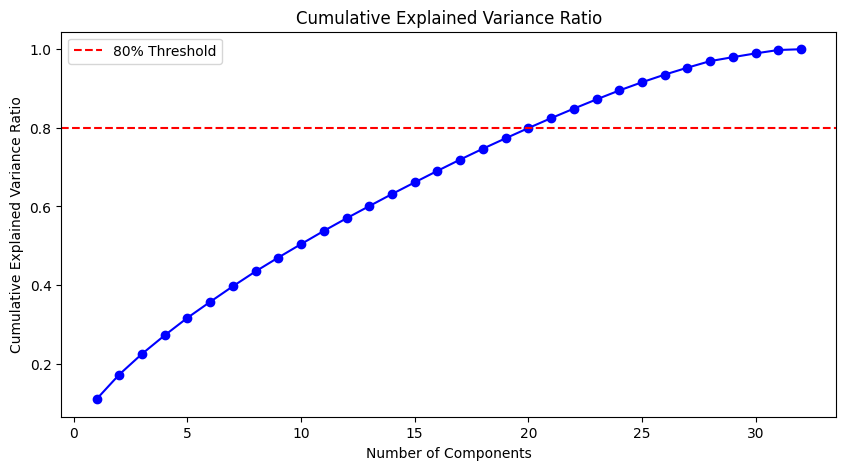

In [310]:
plot_cumulative_variance(pca)

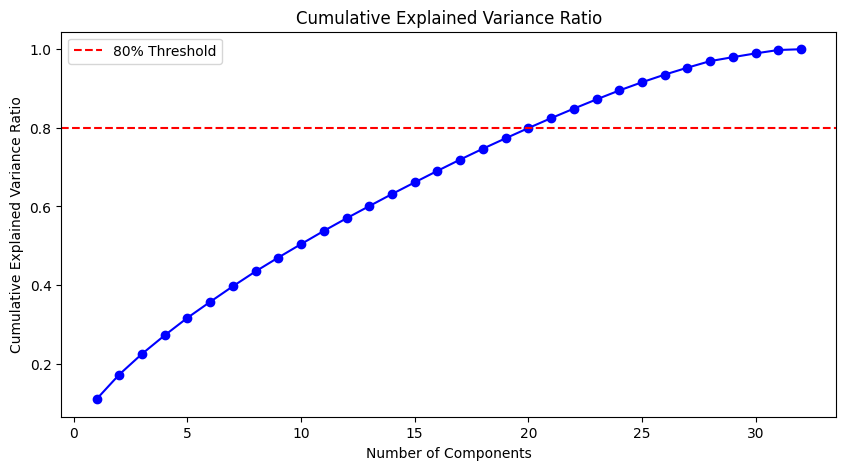

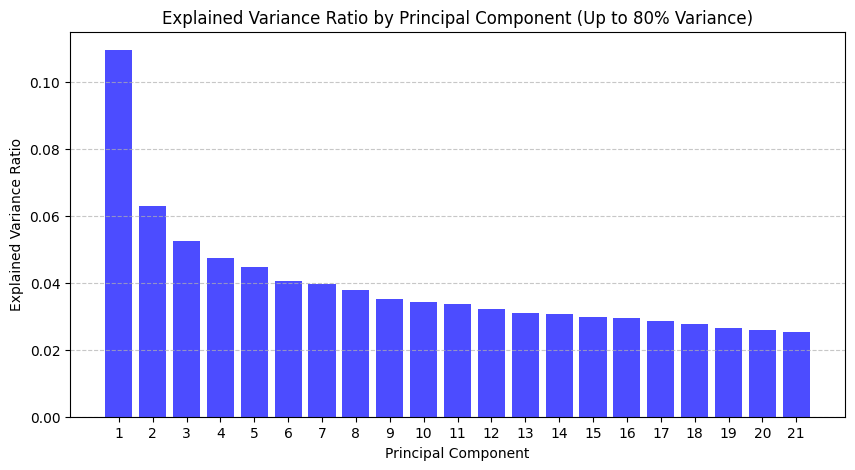

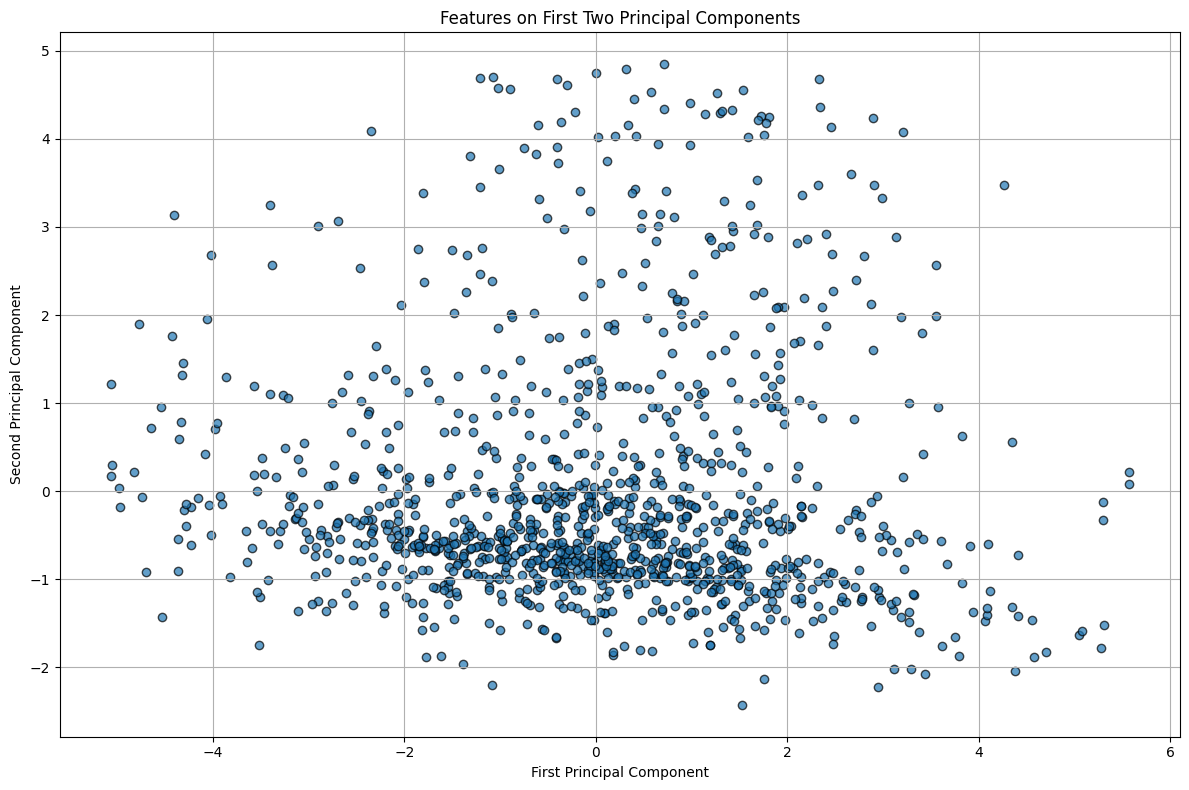

In [311]:
# Plot PCA analysis
plot_cumulative_variance(pca)
plot_explained_variance(pca, n_components)
plot_pca_features(pca, X_pca, n_components)

In [315]:
# Verify PCA feature contributions
loadings_df = plot_feature_loadings(pca, feature_names, n_components)
print("\nFeature Loadings (Top 10 Influential Features):")
print(loadings_df.abs().sum(axis=1).sort_values(ascending=False).head(20))


Feature Loadings (Top 10 Influential Features):
genre_Reality-TV    3.566627
genre_Family        3.528652
genre_Romance       3.505482
genre_Short         3.493026
genre_Comedy        3.488839
genre_Fantasy       3.412723
genre_Sport         3.371890
genre_War           3.366857
genre_Horror        3.346506
genre_Musical       3.344137
genre_Documentary   3.329068
genre_Thriller      3.309864
genre_Mystery       3.276999
genre_Music         3.274263
genre_News          3.223533
genre_Biography     3.209824
genre_Drama         3.128306
genre_Talk-Show     3.106954
genre_Sci-Fi        3.106118
genre_Western       3.030060
dtype: float64



Step 3: Performing clustering analysis...


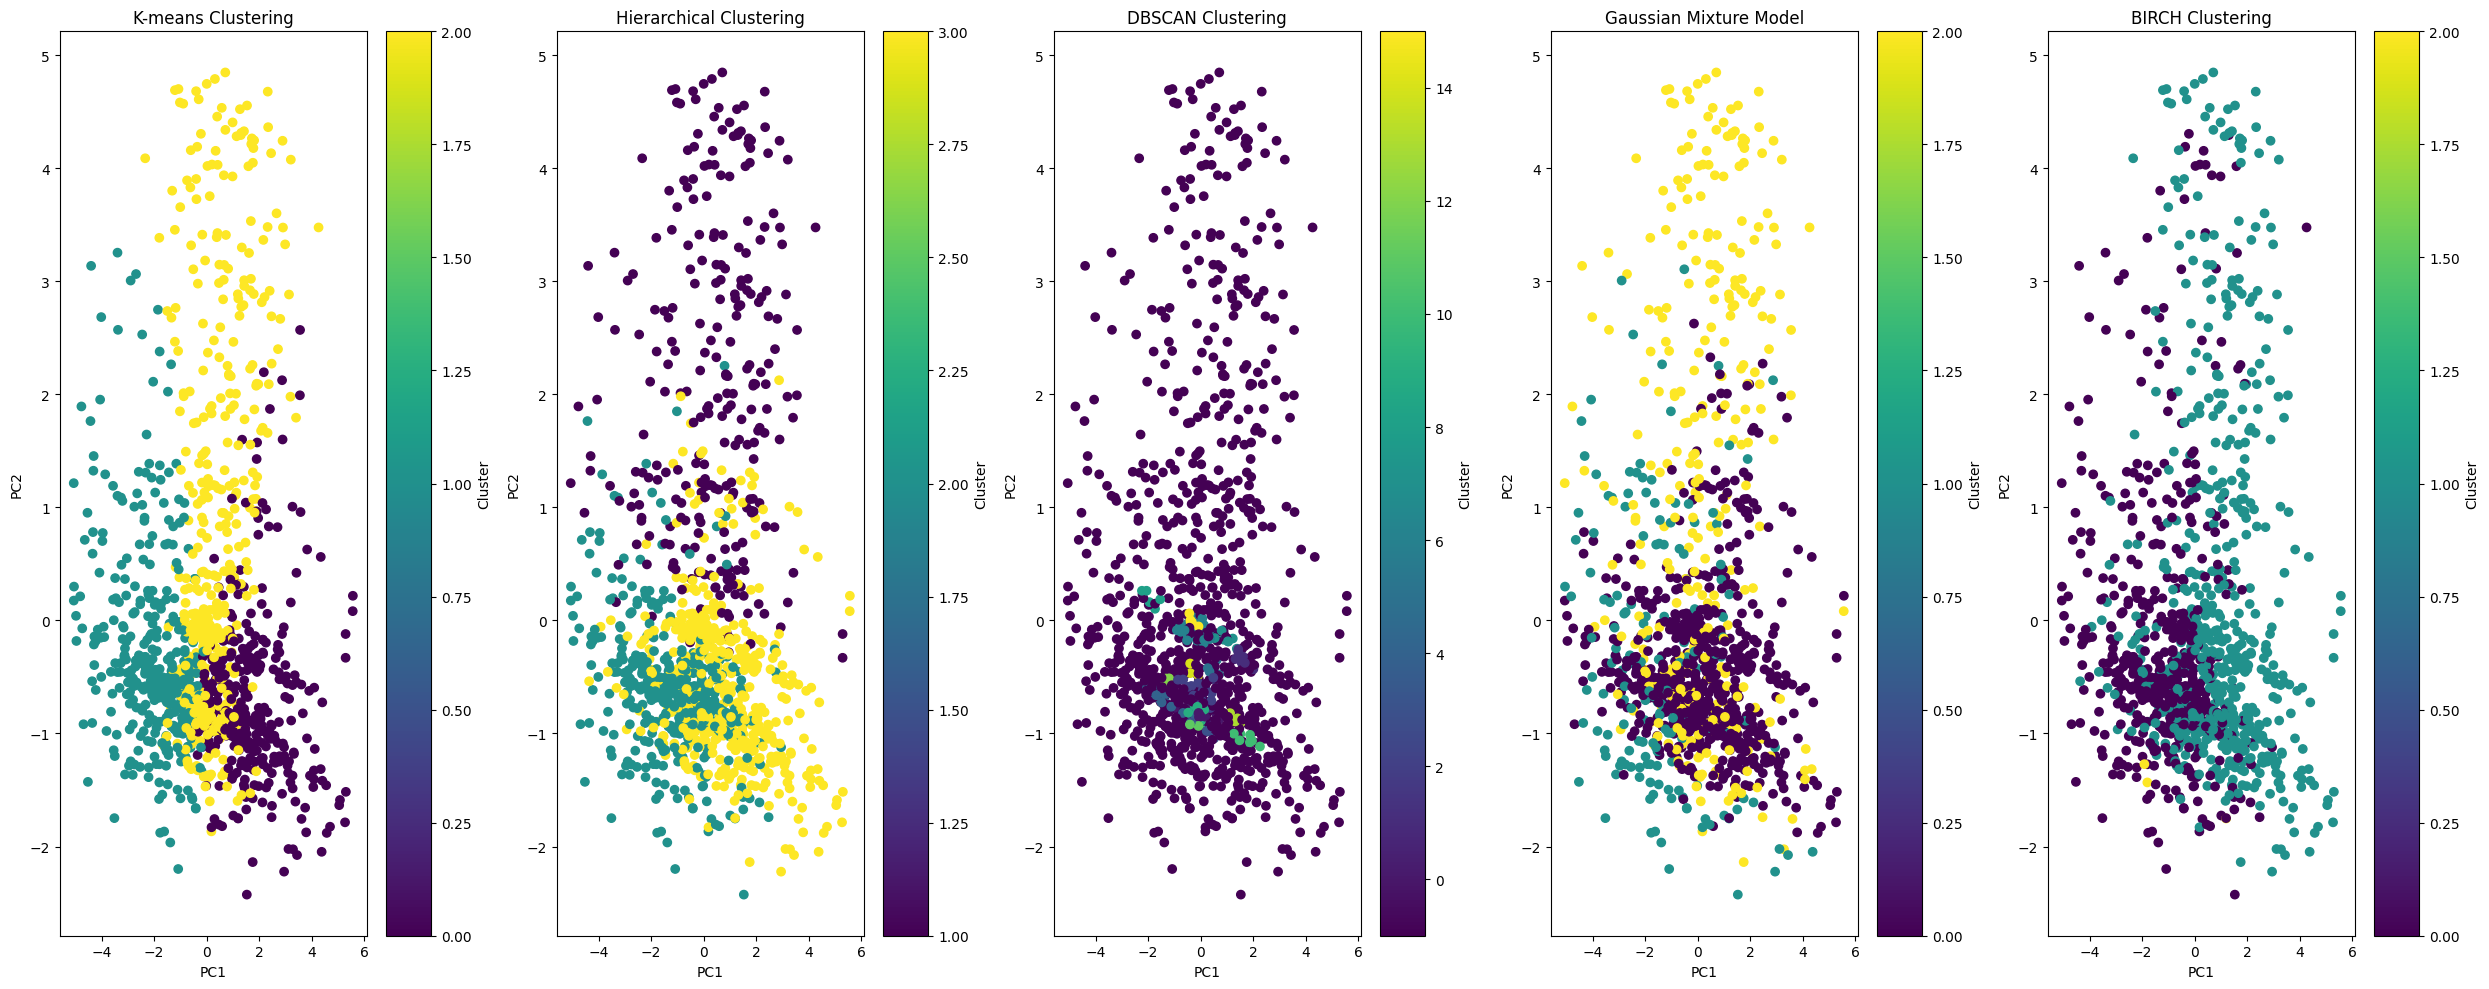

In [313]:
# Perform clustering analysis
print("\nStep 3: Performing clustering analysis...")
plot_clustering_comparison(X_pca, n_components)

In [314]:
# Get evaluation metrics
results_df = analyze_clusters(X_pca)


Clustering Evaluation Results:
      Method  n_clusters  Silhouette Score  Davies-Bouldin Index
     K-means           2          0.075000              3.343000
     K-means           3          0.075000              2.950000
     K-means           4          0.091000              2.646000
     K-means           5          0.098000              2.553000
     K-means           6          0.108000              2.194000
Hierarchical           2          0.081000              4.397000
Hierarchical           3          0.078000              3.483000
Hierarchical           4          0.071000              3.140000
Hierarchical           5          0.059000              2.886000
Hierarchical           6          0.080000              2.650000
         GMM           2          0.178000              4.539000
         GMM           3          0.081000              3.915000
         GMM           4          0.080000              3.826000
         GMM           5          0.089000              3.